# Oregon Wildlife Evaluation

This notebook evaluates every image from the nine Oregon dataset classes that map to the North American wildlife model. Unmapped classes are disclosed and excluded. Folder labels provide image-level ground truth, so these metrics are not bounding-box mAP.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from model_services.image import WildlifeDetector  # noqa: E402
from scripts.evaluate_wildlife_folders import (  # noqa: E402
    OREGON_LABEL_MAP,
    collect_samples,
    evaluate,
)

DATASET_PATH = PROJECT_ROOT / 'data/datasets/oregon_wildlife/oregon_wildlife'
REPORT_PATH = PROJECT_ROOT / 'notebooks/results/oregon_wildlife_report.json'
CONFIDENCE = 0.25
BATCH_SIZE = 32

print(f'CUDA available: {torch.cuda.is_available()}')
device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
print(f'Device: {device_name}')

/home/vivek/Documents/Vivek-projects/WildGuard/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True
Device: NVIDIA GeForce RTX 4090


In [2]:
class_counts = {
    path.name: sum(1 for item in path.iterdir() if item.is_file())
    for path in sorted(DATASET_PATH.iterdir())
    if path.is_dir()
}
policy_rows = [
    {
        'dataset_label': label,
        'images': count,
        'status': 'evaluated' if label in OREGON_LABEL_MAP else 'excluded',
        'model_label': OREGON_LABEL_MAP.get(label),
    }
    for label, count in class_counts.items()
]
policy_df = pd.DataFrame(policy_rows)
display(policy_df)
evaluated_count = policy_df.loc[policy_df.status == 'evaluated', 'images'].sum()
excluded_count = policy_df.loc[policy_df.status == 'excluded', 'images'].sum()
print('Evaluated images:', evaluated_count)
print('Excluded images:', excluded_count)

,dataset_label,images,status,model_label
0,bald_eagle,748,evaluated,bald_eagle
1,black_bear,718,evaluated,black_bear
2,bobcat,696,evaluated,bobcat
3,canada_lynx,717,excluded,NaN
4,columbian_black-tailed_deer,735,evaluated,mule_deer
5,cougar,680,evaluated,mountain_lion
6,coyote,736,evaluated,coyote
7,deer,764,excluded,NaN
8,elk,660,evaluated,elk
9,gray_fox,668,excluded,NaN


Evaluated images: 6359
Excluded images: 7654


In [3]:
samples = collect_samples(
    DATASET_PATH,
    label_map=OREGON_LABEL_MAP,
    samples_per_class=10**9,
    seed=42,
)
print(f'Evaluating {len(samples)} mapped images...')
report = evaluate(
    WildlifeDetector(),
    samples,
    batch_size=BATCH_SIZE,
    confidence=CONFIDENCE,
)
report['dataset_images'] = sum(class_counts.values())
report['evaluated_images'] = len(samples)
report['excluded_images'] = sum(class_counts.values()) - len(samples)
report['policy'] = policy_rows
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
REPORT_PATH.write_text(json.dumps(report, indent=2) + '\n', encoding='utf-8')
print(f'Saved report to {REPORT_PATH}')

Evaluating 6333 mapped images...


WARNING ⚠️ NMS time limit 2.050s exceeded


/home/vivek/Documents/Vivek-projects/WildGuard/.venv/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


/home/vivek/Documents/Vivek-projects/WildGuard/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


Saved report to /home/vivek/Documents/Vivek-projects/WildGuard/notebooks/results/oregon_wildlife_report.json


,images,any_detection,target_detected,top1_correct,detection_rate,target_detection_rate,top1_accuracy
overall,6333,5784,3919,3734,0.913311,0.618822,0.58961


,images,any_detection,target_detected,top1_correct,detection_rate,target_detection_rate,top1_accuracy
bald_eagle,744,671,413,386,0.901882,0.555108,0.518817
black_bear,715,661,465,444,0.924476,0.650350,0.620979
bobcat,690,640,560,542,0.927536,0.811594,0.785507
columbian_black-tailed_deer,735,699,609,587,0.951020,0.828571,0.798639
cougar,673,573,136,122,0.851412,0.202080,0.181278
coyote,736,686,442,421,0.932065,0.600543,0.572011
elk,660,619,518,506,0.937879,0.784848,0.766667
gray_wolf,730,640,320,287,0.876712,0.438356,0.393151
raven,650,595,456,439,0.915385,0.701538,0.675385


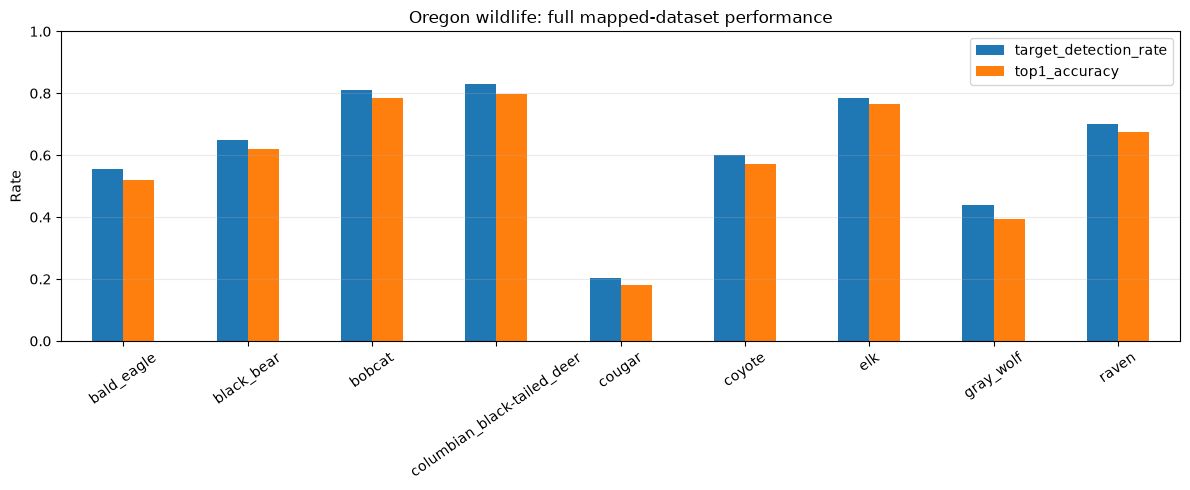

In [4]:
overall_df = pd.DataFrame([report['overall']], index=['overall'])
per_class_df = pd.DataFrame.from_dict(report['per_class'], orient='index')
display(overall_df)
display(per_class_df)

plot_df = per_class_df[['target_detection_rate', 'top1_accuracy']]
ax = plot_df.plot.bar(figsize=(12, 5), ylim=(0, 1), rot=35)
ax.set_title('Oregon wildlife: full mapped-dataset performance')
ax.set_ylabel('Rate')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()